# K-Mers Counting

In [17]:
from Bio import SeqIO
from collections import Counter

def count_kmers_per_genome(fasta_file, k):
    genome_kmers = {}

    for record in SeqIO.parse(fasta_file, "fasta"):
        seq = str(record.seq).upper()
        kmers = Counter()

        for i in range(len(seq) - k + 1):
            kmer = seq[i:i+k]
            if "N" not in kmer:
                kmers[kmer] += 1

        genome_kmers[(record.id).split('.')[0]] = kmers

    return genome_kmers


In [18]:
import pandas as pd

excel_file_path = "../data/journal.pcbi.1012525.s001.xlsx"
sheet_names = pd.ExcelFile(excel_file_path).sheet_names
training = pd.read_excel(excel_file_path, sheet_name=sheet_names[0])
test = pd.read_excel(excel_file_path, sheet_name=sheet_names[1])

# Create a dictionary mapping Accession ID -> Corrected Lifecycle
lifecycle_map = {}
all_metadata = pd.concat([training, test])

# Standardize lifecycle labels and populate the map
for _, row in all_metadata.iterrows():
    acc = row['Accession number']
    raw_life = row['Lifecycle']
    clean_life = "lysogenic" if str(raw_life).strip().lower() in ["lysogneic", "lysogenic"] else "lytic"
    lifecycle_map[acc] = clean_life
all_metadata.set_index(all_metadata.columns[0], inplace=True)
all_metadata.head()

,Lifecycle,Usage,5-fold cross-validation
Accession number,,,
NC_003313,Lysogneic,Training,Group1
NC_003524,Lysogneic,Training,Group1
NC_005294,Lysogneic,Training,Group1
NC_006945,Lysogneic,Training,Group1
NC_007581,Lysogneic,Training,Group1


In [19]:
import os

fasta_path = "../data/data_fasta"
fasta_paths = os.listdir(fasta_path)
kmers_dict_lytic = {}
kmers_dict_lysogenic = {}

print(len(fasta_paths))
for fasta_file in fasta_paths:
    full_path = os.path.join(fasta_path, fasta_file)
    if str(all_metadata.loc[fasta_file.split('.')[0]]['Lifecycle']).lower() == 'lytic':
        kmers_dict_lytic.update(count_kmers_per_genome(full_path, k=8))
    else:
        kmers_dict_lysogenic.update(count_kmers_per_genome(full_path, k=8))

2176


# Lytic analysis

In [20]:
# This automatically aligns keys (k-mers) and fills missing ones with NaN
df_lytic = pd.DataFrame.from_records(list(kmers_dict_lytic.values())).fillna(0)

# Sum columns (k-mers) and get top 20
top20_series = df_lytic.sum().nlargest(100)

# Extract results
kmers_lytic = top20_series.index.tolist()
counts = top20_series.values.tolist()

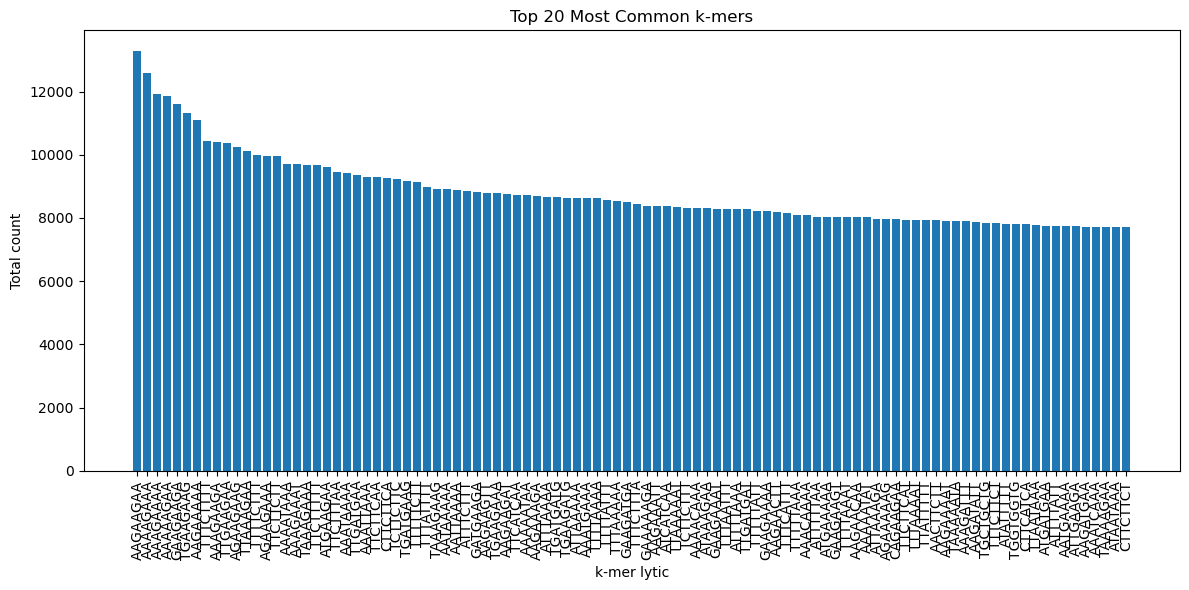

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.bar(kmers_lytic, counts)
plt.xticks(rotation=90)
plt.xlabel("k-mer lytic")
plt.ylabel("Total count")
plt.title("Top 20 Most Common k-mers")
plt.tight_layout()
plt.show()


In [22]:
print(kmers_lytic)

['AAGAAGAA', 'AAAAGAAA', 'AAAGAAAA', 'AAAAAGAA', 'GAAGAAGA', 'TGAAGAAG', 'AAGAAAAA', 'TTTCTTTT', 'AAAGAAGA', 'TTGAAGAA', 'AGAAGAAG', 'TTAAAGAA', 'TTTTCTTT', 'AGAAGAAA', 'TTCTTCTT', 'AAAATAAA', 'AAAGAAAT', 'TAAAGAAA', 'TTCTTTTT', 'ATGAAGAA', 'TTCTTTAA', 'AAATAAAA', 'TTGATGAA', 'AAATTAAA', 'TTCTTCAA', 'CTTCTTCA', 'TCTTCTTC', 'TGATGAAG', 'TTTTTCTT', 'TTTATTTT', 'TAAAGAAG', 'AATAAAAA', 'AATTAAAA', 'ATTTCTTT', 'GATGAAGA', 'AAGAAGTT', 'TGAAGAAA', 'AAGAAGAT', 'TTCATCAA', 'AAAAATAA', 'AAGAAAGA', 'ATTTAAAA', 'TGATGATG', 'TGAAGATG', 'ATTAAAAA', 'AAATGAAA', 'TTTTAAAA', 'TTTTATTT', 'TTTAAAAA', 'GAAGATGA', 'TTTCTTTA', 'GAAAAAGA', 'AAGAAATT', 'ATCATCAA', 'TTAAAAAT', 'TCTTCTTT', 'AAAACAAA', 'ATAAAGAA', 'GAAGAAAT', 'TTTAATTT', 'ATTTTAAA', 'TTGATGAT', 'TTTTTATT', 'GAAGAAAA', 'AAGAACTT', 'TTTCATTT', 'TTTTTAAA', 'AAACAAAA', 'ATTTTTAA', 'ATGAAAAA', 'GAAGAAGT', 'TTTTAAAT', 'AAGAACAA', 'AAAAATAT', 'ATTAAAGA', 'AGAAAAAG', 'CAGAAGAA', 'TTCTTCAT', 'TTTAAAAT', 'TTATTTTT', 'AACTTCTT', 'AAGAAAAT', 'TAAAAATA', 'AA

# Lysogenic Analysis

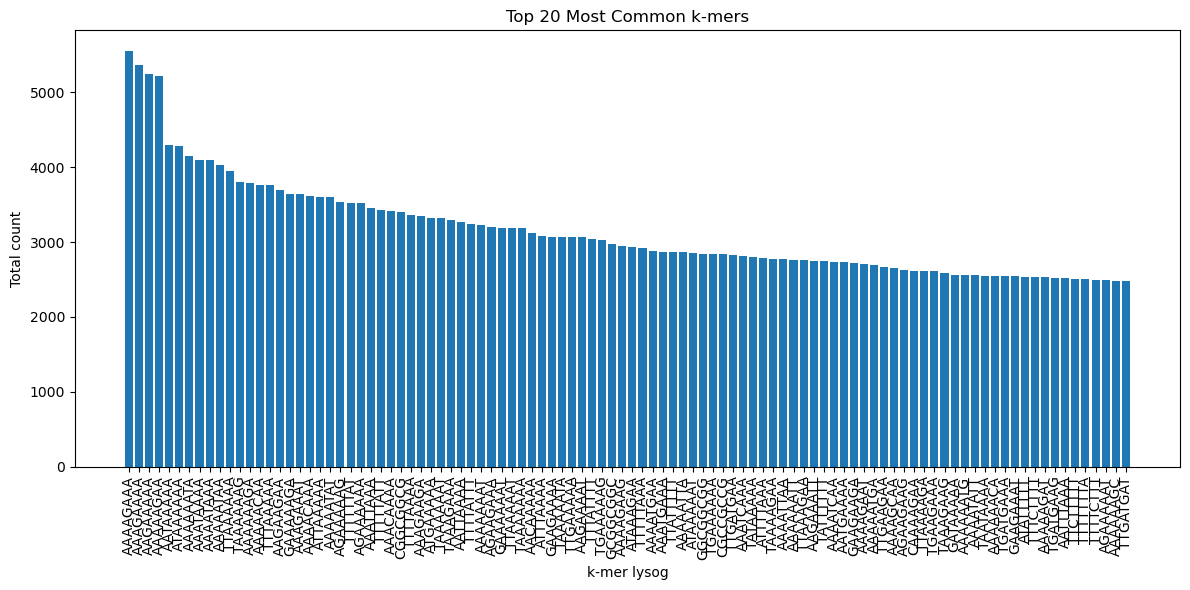

In [23]:
# This automatically aligns keys (k-mers) and fills missing ones with NaN
df_lysogenic = pd.DataFrame.from_records(list(kmers_dict_lysogenic.values())).fillna(0)

# Sum columns (k-mers) and get top 20
top20_series = df_lysogenic.sum().nlargest(100)

# Extract results
kmers_lysogenic = top20_series.index.tolist()
counts = top20_series.values.tolist()

plt.figure(figsize=(12, 6))
plt.bar(kmers_lysogenic, counts)
plt.xticks(rotation=90)
plt.xlabel("k-mer lysog")
plt.ylabel("Total count")
plt.title("Top 20 Most Common k-mers")
plt.tight_layout()
plt.show()

In [24]:
print(kmers_lysogenic)

['AAAAGAAA', 'AAAGAAAA', 'AAGAAAAA', 'AAAAAGAA', 'AATAAAAA', 'ATAAAAAA', 'AAAAAATA', 'AAATAAAA', 'AAAATAAA', 'AAAAATAA', 'TTAAAAAA', 'TAAAAAAG', 'AAAAAAGA', 'AAAAACAA', 'TTTAAAAA', 'AAGAAGAA', 'GAAAAAGA', 'AAAGAAAT', 'AAAACAAA', 'ATTAAAAA', 'AAAAATAT', 'AGAAAAAG', 'TTTTTTAT', 'AGAAAAAA', 'AAATTAAA', 'TTTTTATT', 'AAACAAAA', 'CGGCGGCG', 'TTTTAAAA', 'AAAGAAGA', 'ATGAAAAA', 'TAAAAAAT', 'TAAAGAAA', 'AATTAAAA', 'TTTTATTT', 'AAAAAAAT', 'AGAAGAAA', 'GAAAAAAT', 'TTAAAAAT', 'TAAAAAAA', 'AACAAAAA', 'ATTTAAAA', 'GAAGAAAA', 'TAAAAATA', 'TTGAAAAA', 'AAGAAAAT', 'TTTATTTT', 'TGAAAAAG', 'GCGGCGGC', 'AAAAGAAG', 'ATAAAGAA', 'TTTTTAAA', 'AAAATGAA', 'AAATGAAA', 'TTATTTTT', 'AAAAATTA', 'ATAAAAAT', 'GGCGGCGG', 'TGAAAAAA', 'CGCCGCCG', 'TTGATGAA', 'AAATCAAA', 'TATAAAAA', 'ATTTTAAA', 'TAAAAGAA', 'AAAATTAA', 'AAAAAATT', 'TTAAAGAA', 'AAGAAATT', 'TATTTTTT', 'AAAATCAA', 'AATGAAAA', 'GAAGAAGA', 'AAAAGAAT', 'AAAAATGA', 'TTGAAGAA', 'AAAAGCAA', 'AGAAGAAG', 'CAAAAGAA', 'TTAAAAGA', 'TGAAGAAA', 'TAAAGAAG', 'GATAAAAA', 'AA

In [25]:
print(set(kmers_lysogenic) - set(kmers_lytic))
print(set(kmers_lytic) - set(kmers_lysogenic))

{'AAAAGAAT', 'GAAAAAAT', 'AAAATATT', 'TTAAAAAA', 'AAAAACAA', 'TTTTTTAT', 'TTGAAAAA', 'ATAAAAAA', 'AAAAAAGC', 'TGATGAAA', 'TAAAAAAT', 'TAAAAAAA', 'AAAAGAAG', 'AACAAAAA', 'AAAAAAGA', 'AAAAAATT', 'TATTTTTT', 'TTAAAAGA', 'AAAAATTA', 'TTTTTTTA', 'GCGGCGGC', 'CGCCGCCG', 'AAAAAAAT', 'TGAAAAAA', 'AGAAAAAA', 'CAAAAGAA', 'AAAATTAA', 'AAAAATGA', 'AAAAGCAA', 'TAATAAAA', 'GGCGGCGG', 'TATAAAAA', 'CGGCGGCG', 'TAAAAAAG', 'AATTTAAA', 'AAAATCAA', 'AAAAAATG', 'AAAAAACA', 'GATAAAAA', 'AAAAAATA', 'AAAATGAA', 'ATAAAAAT', 'AGAAAAAT', 'TGAAAAAG', 'AAAAAGAT'}
{'ATTTTTAA', 'AAGAAAGA', 'TTCTTTAA', 'TGAAGAAG', 'ATTTCTTT', 'TCTTCTTC', 'ATTTTATT', 'TTAATAAA', 'ATGAAGAA', 'CTTCATCA', 'AAGATATT', 'AACTTCTT', 'TTTCTTCT', 'CTTCTTCA', 'TTTTTCTT', 'TTCTTCAT', 'TTCATCAA', 'GAAGAAGT', 'ATTAAAGA', 'ATTGAAGA', 'TTTTAAAT', 'GAAGATGA', 'AAGAAGTT', 'AAGAAGAT', 'AAAGATTT', 'TTTAAAAT', 'TGATGATG', 'TGGTGGTG', 'TCTTCTTT', 'TGCTGCTG', 'AAGAACAA', 'AAGATGAA', 'TTTCATTT', 'CTTCTTCT', 'ATGATGAA', 'TTCTTCTT', 'GATGAAGA', 'ATAATAAA', 'T

In [26]:
import torch
import numpy as np
# Load the file using the path exactly as it was saved
# file_path = '../data/embeddings_171225_2176_32768_blocks.28.mlp.l3.pt'
file_path = '../data/embeddings_2026-1-10_15-24-10_2176_32768_blocks.28.mlp.l3_16384_0.pt'
data = torch.load(file_path, map_location=torch.device('cpu'))

# Extract the lists from the dictionary
ids = data["ids"]               # List of strings
# DeepPL files contains accession id without version number, so we need to erase it from our ids
ids = [item.split('.')[0] for item in ids] 
embeddings_list = data["embeddings"] # List of torch.Tensors
starts_list = data['starts']
ends_list = data['ends']

# Convert to arrays (if they aren't already)
starts_arr = np.array(starts_list)
ends_arr = np.array(ends_list)
ids_arr = np.array(ids)
emb_arr = np.array(embeddings_list)

# Create a mask of items to KEEP
mask = (ends_arr - starts_arr) >= 16384

# Apply mask to all arrays
filtered_ids = ids_arr[mask]
filtered_embeddings = emb_arr[mask]
filtered_starts = starts_arr[mask]
filtered_ends = ends_arr[mask]

# Convert to Numpy array
loaded_embeds = filtered_embeddings
loaded_ids = np.array(filtered_ids)

# Sanity checks
# assert len(ids) == loaded_embeds.shape[0] == len(filtered_starts) == len(filtered_ends)

print("IDs array shape:", loaded_ids.shape)
print("Embeddings array shape:", loaded_embeds.shape) 

df = pd.DataFrame(
    data=loaded_embeds[:,:],
    index=loaded_ids[:],
    columns=[[f"feature_{i}" for i in range(len(loaded_embeds[0]))]]
) 

# Take a look
df.head()

IDs array shape: (8391,)
Embeddings array shape: (8391, 4096)


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_4086,feature_4087,feature_4088,feature_4089,feature_4090,feature_4091,feature_4092,feature_4093,feature_4094,feature_4095
NC_012663,47.00,-93.00,-69.50,96.5,102.000000,-44.00,-122.0,44.000,-75.0,-268.0,...,-41.75,36.000,-59.00,-62.75,-59.5,82.0000,80.500,-116.5,-74.50,0.750000
NC_012663,46.00,-93.00,-75.00,94.5,97.500000,-42.00,-120.0,41.750,-81.5,-260.0,...,-41.00,32.250,-61.00,-62.50,-61.5,78.0000,80.500,-112.5,-78.50,-6.781250
NC_012663,46.25,-94.00,-75.50,92.5,102.000000,-39.00,-116.5,40.250,-84.0,-249.0,...,-41.50,30.125,-62.50,-65.50,-66.0,75.5000,85.000,-110.5,-70.00,-14.000000
NC_025467,58.25,-94.00,-83.50,96.5,103.000000,-48.75,-115.5,43.750,-69.0,-276.0,...,-51.00,38.000,-58.00,-56.75,-55.5,100.0000,83.000,-121.0,-23.75,-24.125000
AJ298298,26.50,-56.25,-41.25,127.5,3.359375,-19.75,-121.0,15.625,-76.0,-131.0,...,-20.75,11.250,-36.25,-35.50,-23.0,12.6875,24.375,-103.5,-40.25,-3.265625


In [27]:
# Path to the Excel file containing lifecycle information
excel_file_path = "../data/journal.pcbi.1012525.s001.xlsx"
# Training
sheet_names = pd.ExcelFile(excel_file_path).sheet_names
# Training dataset
training = pd.read_excel(excel_file_path, sheet_name=sheet_names[0])
# Test dataset
test = pd.read_excel(excel_file_path, sheet_name=sheet_names[1])

# Create a dictionary mapping Accession ID -> Corrected Lifecycle
lifecycle_map = {}
all_metadata = pd.concat([training, test])

# Standardize lifecycle labels and populate the map
for _, row in all_metadata.iterrows():
    acc = row['Accession number']
    raw_life = row['Lifecycle']
    clean_life = "lysogenic" if str(raw_life).strip().lower() in ["lysogneic", "lysogenic"] else "lytic"
    lifecycle_map[acc] = clean_life

# Create aligned list
aligned_lifecycles = []
for accession in df.index:
    if accession in lifecycle_map:
        aligned_lifecycles.append(lifecycle_map[accession])
    else:
        # Warning only once per missing ID to avoid clutter
        print(f"Warning: Accession {accession} not found. Defaulting to lytic.")
        aligned_lifecycles.append("lytic") 

aligned_lifecycles = np.array(aligned_lifecycles)
print(f"Aligned labels length: {len(aligned_lifecycles)}")

Aligned labels length: 8391


In [28]:
from sklearn import preprocessing
# Set global random state for following models
RANDOM_STATE = 0

train_ids = set(training['Accession number'].astype(str).str.strip())
test_ids = set(test['Accession number'].astype(str).str.strip())

# Prepare feature and labels
train_indices = []
test_indices = []
y_train = []
y_test = []

for i, accession in enumerate(df.index):
    label = lifecycle_map.get(accession, "lytic")
    
    if accession in train_ids:
        train_indices.append(i)
        y_train.append(label)
    elif accession in test_ids:
        test_indices.append(i)
        y_test.append(label)


X_train = df.iloc[train_indices]
X_test = df.iloc[test_indices]
y_train = np.array(y_train)
y_test = np.array(y_test)

# Normalize data (row-wise)
normalizer = preprocessing.Normalizer()
X_train = normalizer.transform(X_train)
X_test = normalizer.transform(X_test)

print(f"Data Split Loaded: {len(X_train)} Train, {len(X_test)} Test")


Data Split Loaded: 6939 Train, 1452 Test


In [29]:
from joblib import load
from utils import compute_and_print_metrics
# We import svaed model tuned on normalized data and summed embeddings
# With these, we only use it in inference mode
# f1_scorer = make_scorer(f1_score, pos_label="lysogenic")
model = load("hgb_model.joblib")
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

y_pred = np.concat([y_train_pred, y_test_pred])
y_true = np.concat([y_train, y_test])
# Statistics on the entire dataset
compute_and_print_metrics("HGB Model", y_true, y_pred, pos_label="lysogenic")
# Statistics on test set only
compute_and_print_metrics("HGB Model - Test", y_test, y_test_pred, pos_label="lysogenic")


HGB Model RESULTS
------------------------------
Sensitivity (Recall): 0.8344
Specificity:          0.9793
Accuracy:             0.9515
F1-Score:             0.8686
MCC:                  0.8400
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic      6639             140
Actual lysogenic   267            1345

HGB Model - Test RESULTS
------------------------------
Sensitivity (Recall): 0.7449
Specificity:          0.9888
Accuracy:             0.9394
F1-Score:             0.8327
MCC:                  0.8046
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic      1145              13
Actual lysogenic    75             219
